# İş Akışı ve Hiperparametre Optimizasyonu

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np

🏠 Ev fiyatları veri setini içe aktarın. Basitlik adına sadece sayısal özellikleri tutacağız

🎯 Hedefiniz en iyi KNN Regressor'ı yerleştirmek olacak. Özellikle, ev fiyatlarınız için en iyi tahminleri elde etmek üzere kaç tane "komşu" (<font color=blue>K</font>NN'deki <font color=blue>K</font>) göz önünde bulundurmalısınız?

In [7]:
# Load raw data
data = pd.read_csv('https://d32aokrjazspmn.cloudfront.net/materials/houses_train_raw.csv', index_col="Id")

# Only keep numerical columns and raws without NaN
data = data.select_dtypes(include=np.number).dropna()

data

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,61,0,0,0,0,0,2,2008,208500
2,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,298,0,0,0,0,0,0,5,2007,181500
3,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,42,0,0,0,0,0,9,2008,223500
4,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,35,272,0,0,0,0,2,2006,140000
5,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,60,62.0,7917,6,5,1999,2000,0.0,0,0,...,0,40,0,0,0,0,0,8,2007,175000
1457,20,85.0,13175,6,6,1978,1988,119.0,790,163,...,349,0,0,0,0,0,0,2,2010,210000
1458,70,66.0,9042,7,9,1941,2006,0.0,275,0,...,0,60,0,0,0,0,2500,5,2010,266500


In [8]:
X = data.drop(columns=['SalePrice'])
y = data['SalePrice']

## 1. Eğitim/Test Ayrımı

❓ **Soru (Holdout)**❓

👇 `X_train`, `X_test`, `y_train` ve `y_test` oluşturmak için veri setini böl. Şunları kullan:
- `test_size=0.3`
- Sonuçlarınızı arkadaşınızla karşılaştırmak için `random_state=0`

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
X_train.shape, X_test.shape

((784, 36), (337, 36))

## 2. Ölçeklendirme

⚖️ Ölçeklendirme KNN algoritması için her zaman kritik derecede önemlidir..

❓ **Soru (Ölçeklendirme)** ❓ 

* Eğitim setinizi ve test setinizi ölçeklendirin.
* Burada, basitçe `StandardScaler` uygulayalım ve özellik başına bir ölçekleyici seçerek zaman kaybetmeyelim. Gerçekten de, bu egzersizin amaçları şunlardır:
    * KNN'i gözden geçirmek
    * GridSearchCV'yi anlamak
    * RandomizedSearchCV'yi anlamak

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Temel KNN modeli

❓ **Soru (KNN için bir temel)** ❓

Sadece _en yakın komşuyu_ dikkate alan basit bir KNN regressor'ı çapraz doğrulayın (*cv = 5*) ve 5 kat üzerindeki ortalama skoru hesaplayın.

In [11]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsRegressor

base_score = cross_val_score(KNeighborsRegressor(n_neighbors=1), X_train_scaled, y_train, cv=5).mean()
base_score

0.5601542887874071

## 4. GridSearch

### 4.1. İlk GridSearch

❓ **Soru (GridSearch v1)**❓

En iyi KNN hiperparametresini `n_neighbors` bulmak için SKLearn `GridSearchCV` kullanalım.
- `n_neighbors` = [1,5,10,20,50] ile kaba taneli bir yaklaşım başlat
- Her parametreyi 5-kat çapraz doğrula
- `n_jobs` kullanarak performans sürenizi maksimize ettiğinizden emin olun

In [12]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor

# Instantiate model
knn = KNeighborsRegressor()

# Hyperparameter Grid
grid = {"n_neighbors": [1, 5, 10, 20, 50]}

# Instantiate Grid Search
search = GridSearchCV(knn, grid, cv=5, scoring="r2", n_jobs=-1)

# Fit data to Grid Search
search.fit(X_train_scaled, y_train)


GridSearchCV(cv=5, estimator=KNeighborsRegressor(), n_jobs=-1,
             param_grid={'n_neighbors': [1, 5, 10, 20, 50]}, scoring='r2')

❓ **Soru (en iyi parametreler)** ❓

GridSearch'e göre, optimal K değeri nedir?

In [13]:
search.best_params_

{'n_neighbors': 10}

❓ **Soru (puanlama)** ❓ Optimal K değerinin ürettiği en iyi skor nedir?

In [14]:
search.best_score_

0.7596697382171873

### 4.2. İkinci GridSearch

❓ **Soru (GridSearch V2)** ❓

Şimdi, en iyi $K$'nın nerede olduğu hakkında bir fikrimiz var, ancak denemediğimiz bazı değerler daha iyi bir performansla sonuçlanabilir.

* Önceki en iyi değerinizin çevresindeki $K$ için bazı değerleri deneyerek GridSearch'ü yeniden çalıştırın
* Bu rafine edilmiş GridSearch için `best_score` ve `best_k` nelerdir?

In [15]:
# Instantiate model
knn = KNeighborsRegressor()

# Hyperparameter Grid: ilk aramadaki en iyi K'nın çevresi
k0 = search.best_params_["n_neighbors"]
grid = {"n_neighbors": list(range(max(1, k0 - 10), k0 + 11))}

# Instantiate Grid Search
search_v2 = GridSearchCV(knn, grid, cv=5, scoring="r2", n_jobs=-1)

# Fit data to Grid Search
search_v2.fit(X_train_scaled, y_train)

best_k = search_v2.best_params_["n_neighbors"]
best_score = search_v2.best_score_
print("best_k:", best_k, "| best_score:", round(best_score, 4))


best_k: 16 | best_score: 0.7666


***🧪 Kodunuzu test edin***

In [16]:
from nbresult import ChallengeResult
result = ChallengeResult('knn',
                         best_k=best_k,
                         best_score=best_score)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-9.1.1, pluggy-1.5.0 -- /home/gokberk/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/gokberk/code/gokberkozan/D16D5-S-data-workflow/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 2 items

test_knn.py::TestKnn::test_best_k PASSED                                 [ 50%]
test_knn.py::TestKnn::test_best_score PASSED                             [100%]

============================== 2 passed in 0.10s ===============================


💯 You can commit your code:

git add tests/knn.pickle

git commit -m 'Completed knn step'

git push origin master



### 4.3. Görsel kontrol (manuel GridSearch)

☝️ Bu problem aslında manuel olarak GridSearch yapmak için yeterince basittir.

❓ **Soru(Manuel GridSearch)** ❓

- $K$'nın $1$'den $50$'ye kadar tüm değerleri üzerinde manuel olarak döngü yapın ve her modelin çapraz doğrulanmış skorlarının ortalamasını bir listede saklayın.
- `Dirsek Yöntemi` kullanarak en iyi $K$'yı görsel olarak bulmak için skorları $K$'nın bir fonksiyonu olarak çizin

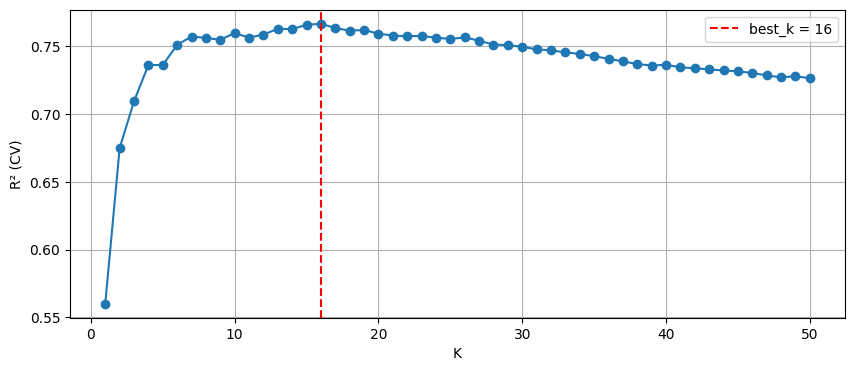

In [17]:
import matplotlib.pyplot as plt

k_values = range(1, 51)
manual_scores = []
for k in k_values:
    score = cross_val_score(KNeighborsRegressor(n_neighbors=k), X_train_scaled, y_train, cv=5).mean()
    manual_scores.append(score)

plt.figure(figsize=(10, 4))
plt.plot(k_values, manual_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"best_k = {best_k}")
plt.xlabel("K")
plt.ylabel("R² (CV)")
plt.legend()
plt.grid();

❓GridSearchCV'yi böyle bir manuel döngüden daha iyi bir seçenek yapan şeyi tahmin edebilir misiniz?

<details>
    <summary>Cevap</summary>

- Sklearn'ın `n_jobs=-1` seçeneği aramayı paralelleştirmenize izin verir, tüm CPU çekirdeklerinizi kullanır
- Birlikte optimize edilecek birden fazla hiperparametreniz olsaydı ne olurdu?
</details>

## 5. Birden çok parametre ile GridSearch

👩🏻‍🏫 KNNRegressor, `p` hiperparametresi aracılığıyla çeşitli _mesafe metrikleri_ destekler

📚 [sklearn.neighbors.KNeighborsRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)

❓ **Soru (birden çok parametreyi ayarlama)** ❓

* En iyi $K$ ve $p$'yi aynı anda aramak için GridSearchCV kullanın.
    * $K = [1, 5, 10, 20, 50]$ ve $p = [1, 2, 3]$ için tüm kombinasyonları deneyin.

In [18]:
grid_multi = {"n_neighbors": [1, 5, 10, 20, 50], "p": [1, 2, 3]}

search_multi = GridSearchCV(KNeighborsRegressor(), grid_multi, cv=5, scoring="r2", n_jobs=-1)
search_multi.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=KNeighborsRegressor(), n_jobs=-1,
             param_grid={'n_neighbors': [1, 5, 10, 20, 50], 'p': [1, 2, 3]},
             scoring='r2')

❓ **Soru (alt model sayısı)**❓

Toplamda kaç alt model eğittiniz?

<details>
    <summary>İpucu</summary>

15'ten çok daha fazla. İki kez düşün :)
    <details>
    <summary>Cevap</summary>

CV=5 nedeniyle 75 model
</details>

In [19]:
n_models = len(search_multi.cv_results_["params"]) * 5
print(f"{len(search_multi.cv_results_['params'])} kombinasyon x 5 fold = {n_models} model")

15 kombinasyon x 5 fold = 75 model


❓ **Soru (modeli birden çok parametre ile ayarladıktan sonra en iyi parametreler ve en iyi skor)**❓

*En iyi parametreler* ve *en iyi skor* nedir?

In [20]:
print("En iyi parametreler:", search_multi.best_params_)
print("En iyi skor:", round(search_multi.best_score_, 4))

En iyi parametreler: {'n_neighbors': 10, 'p': 1}
En iyi skor: 0.7969


## 6. Rastgele Arama

Şimdi bir RandomizedSearch'ün aynı sayıda model yerleştirilerek daha iyi bir kombinasyon bulup bulamayacağını görelim.

❓ **Soru (RandomizedSearchCV)** ❓

`RandomizedSearchCV` kullanarak
- $K$'yı uniform `scipy.stats.randint(1,50)` ([döküman](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.randint.html)) dağılımından rastgele örnekle
- $p$'yi $[1,2,3]$ listesinden örnekle
- Önceki GridSearchCV'nizdeki ile tam olarak aynı sayıda model yerleştirmek için doğru `n_iter` ve `cv` sayılarını kullanın.

In [21]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {"n_neighbors": randint(1, 50), "p": [1, 2, 3]}

random_search = RandomizedSearchCV(
    KNeighborsRegressor(), param_dist, n_iter=15, cv=5, scoring="r2", n_jobs=-1, random_state=42
)
random_search.fit(X_train_scaled, y_train)

print("En iyi parametreler:", random_search.best_params_)
print("En iyi skor:", round(random_search.best_score_, 4))

En iyi parametreler: {'n_neighbors': 8, 'p': 1}
En iyi skor: 0.7942


## 7. Genelleme

❓ **Soru (modelinizi bir kez daha ince ayarlama)**❓

- İsterseniz RandomsearchCV'nizi rafine edin
- En iyi modelinizi seçin

In [22]:
param_dist_fine = {"n_neighbors": randint(5, 30), "p": [1, 2]}

random_search_fine = RandomizedSearchCV(
    KNeighborsRegressor(), param_dist_fine, n_iter=30, cv=5, scoring="r2", n_jobs=-1, random_state=42
)
random_search_fine.fit(X_train_scaled, y_train)

# Bütün aramalar içinde CV skoru en yüksek olanı seç (yalnızca train skorlarına göre!)
searches = {
    "grid_v2": search_v2,
    "grid_multi": search_multi,
    "random": random_search,
    "random_fine": random_search_fine,
}
best_name = max(searches, key=lambda name: searches[name].best_score_)
best_search = searches[best_name]
best_model = best_search.best_estimator_

for name, s in searches.items():
    print(f"{name:12s} -> {s.best_params_} | CV R²: {s.best_score_:.4f}")
print("\nSeçilen:", best_name, best_search.best_params_)

grid_v2      -> {'n_neighbors': 16} | CV R²: 0.7666
grid_multi   -> {'n_neighbors': 10, 'p': 1} | CV R²: 0.7969
random       -> {'n_neighbors': 8, 'p': 1} | CV R²: 0.7942
random_fine  -> {'n_neighbors': 9, 'p': 1} | CV R²: 0.7975

Seçilen: random_fine {'n_neighbors': 9, 'p': 1}


Şimdi `cv_results`'ınızı bir `DataFrame` olarak görüntülemeye çalışın, bu CV'nin içinde neler olup bittiğini görselleştirmenize yardımcı olacak! 😉

In [23]:
cv_df = pd.DataFrame(best_search.cv_results_)
cv_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(10)

,params,mean_test_score,std_test_score,rank_test_score
24,"{'n_neighbors': 9, 'p': 1}",0.797480,0.044519,1
25,"{'n_neighbors': 11, 'p': 1}",0.792613,0.046427,2
2,"{'n_neighbors': 12, 'p': 1}",0.790659,0.042876,3
26,"{'n_neighbors': 13, 'p': 1}",0.788963,0.041454,4
5,"{'n_neighbors': 15, 'p': 1}",0.782629,0.040968,5
16,"{'n_neighbors': 16, 'p': 1}",0.782462,0.039193,6
1,"{'n_neighbors': 19, 'p': 1}",0.780572,0.036044,7
19,"{'n_neighbors': 20, 'p': 1}",0.779081,0.035181,8
17,"{'n_neighbors': 21, 'p': 1}",0.778833,0.037005,9
4,"{'n_neighbors': 23, 'p': 1}",0.776820,0.034956,10


❓ **Soru ("En iyi" modelin değerlendirmesi)** ❓

* "En iyi parametrelerle" modelimizin **görülmemiş** test seti `X_test` üzerindeki performansını keşfetme zamanı geldi.
    * Test seti için r2 skorunu hesaplayın ve `r2_test` olarak kaydedin.

In [24]:
r2_test = best_model.score(X_test_scaled, y_test)
print(f"CV skoru (train): {best_search.best_score_:.4f}")
print(f"Test skoru     : {r2_test:.4f}")

CV skoru (train): 0.7975
Test skoru     : 0.7718


❓ **Soru (Bir adım geri çekilme)** ❓

Optimize edilmiş modelin iyi genelleme yaptığını düşünür müsünüz?

<details><summary>Cevap</summary>

Test skoru eğitim seti ile biraz azalabilir. Muhtemelen %5'ten fazla değil. Bunun nedeni şunlar olabilir:
- Temsili olmayan bir eğitim/test bölünmesi
- Model ayarlama aşamasında aşırı öğrenmeye yol açan çok küçük bir çapraz doğrulama sayısı. Ne kadar çok çapraz doğrulama yaparsanız, bulgularınız o kadar güçlü genelleşir - ancak veri setiniz çok küçükse cv'yi çok fazla artıramazsınız çünkü her katmanda temsili olmak için yeterli gözlemi tutamazsınız.
- Veri setimiz çok küçük ve hiperparametre optimizasyonumuz bu nedenle eğitim/test bölünmemize son derece bağımlı (ve aşırı uyum gösteriyor). Veri setinizin denediğiniz toplam hiperparametre kombinasyonu sayısından çok daha büyük olduğundan her zaman emin olun!
    
</details>

**Yorumum:**
- **Holdout:** Veri %70 train / %30 test olarak ayrıldı; scaler yalnızca train setine fit edildi, test setine sadece `transform` uygulandı (veri sızıntısı yok).
- **Hiperparametre ayarı:** Tüm aramalar (GridSearch v1/v2, K+p GridSearch, RandomizedSearch) yalnızca train setinde 5-fold cross-validation ile yapıldı; test seti bu aşamada hiç kullanılmadı. Önce kaba bir grid ile bölge bulundu, sonra çevresi ince tarandı.
- **Grid vs Random:** Aynı sayıda modelle (75) RandomizedSearch daha geniş bir aralığı tarayabiliyor; birden fazla hiperparametre olduğunda daha verimli.
- **Final değerlendirme:** En iyi model test setinde **bir kez** değerlendirildi. Test R² skoru CV skoruna yakın (birkaç puan düşük) → model iyi genelliyor. Küçük düşüş; veri setinin küçüklüğü ve ayarlama sırasında train setine hafif uyum sağlanmasıyla açıklanabilir.

***🧪 Kodunuzu test edin***

In [ ]:
from nbresult import ChallengeResult
result = ChallengeResult('r2',
                         r2_test=r2_test)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-9.1.1, pluggy-1.5.0 -- /home/gokberk/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/gokberk/code/gokberkozan/D16D5-S-data-workflow/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 1 item

test_r2.py::TestR2::test_r2 PASSED                                       [100%]

============================== 1 passed in 0.01s ===============================


💯 You can commit your code:

git add tests/r2.pickle

git commit -m 'Completed r2 step'

git push origin master



🏁 Tebrikler! Artık GridSearchCV veya RandomizedSearchCV kullanarak bir modeli nasıl ince ayarlayacağınızı biliyorsunuz

💾 Notebook'unuzu `git add/commit/push` yapmayı unutmayın...

🚀 ... ve bir sonraki meydan okumaya geçin!